# ZShooter resolution and detector sampling

Executed companion to [the resolution and sampling note](../docs/resolution-and-sampling.md). Run all cells to regenerate its tables and figures for the detector modes listed below.

The optical prescription, slit, effective PSF, spectral projection and detector WCS come from the configured train. Detector type and pitch are read from its native detector headers; the mode names do not imply fixed detector specifications. We compare geometric full-slit sampling and a narrow line's measured FWHM as its position moves across one detector pixel.

These are noiseless shape experiments: throughput, atmosphere and detector noise are not applied. The line has input $R_{\mathrm{FWHM}}=200{,}000$. We integrate the complete spatial cutout so extraction-width changes cannot cause the measured differences. Acceptance checks are 1% flux, 2% FWHM and 0.01 native pixel centroid under quadrature refinement; pixel-phase variation is measured separately.

In [1]:
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.wcs import WCS
import scopesim as sim
from zs_scopesim_tools.helpers import configure_irdb_path, set_scopesim_log_level
from zs_scopesim_tools.paths import repo_root

root = repo_root()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from validation.xshooter.resolution_sampling import isolated_profile

configure_irdb_path()
set_scopesim_log_level('error')
output = root/'validation/xshooter/data/resolution_sampling'
output.mkdir(exist_ok=True)
DETECTOR_MODES = ('SPEC', 'SPEC_ALTDETECT')
cases = [('natural .70', .70, False), ('natural .33', .33, False), ('AO .33', .33, True)]
properties = {'!OBS.mjdobs': 60310.25, '!OBS.seeing': .65, '!OBS.airmass': 1.1}


## Project configured slit edges and isolated lines

Slit-edge separation and geometric resolving power use the trace's `slit_dispersion`; detector coordinates come from its native WCS. Geometry is sampled across every primary FSR, with detector coverage retained separately. Each line experiment uses the middle configured order, the existing PSF/slit projection helper, 17 pixel positions and a quadrature refinement at the midpoint. No geometry or detector values are cached between modes.

In [2]:
started = perf_counter()
geometry_rows, phase_rows, profile_rows, checks, detector_rows, timings = [], [], [], [], [], []
for mode in DETECTOR_MODES:
    for name, slit, ao in cases:
        setup_start = perf_counter()
        commands = sim.UserCommands(use_instrument='ZShooter_v2', set_modes=[mode], properties=properties | {'!INST.vis_curr_slit': slit, '!INST.nir_curr_slit': slit})
        for document in commands.yaml_dicts:
            if 'effects' in document:
                document['effects'] = [effect for effect in document['effects'] if effect['name'] not in ('atmo_transmission', 'continuum_emission', 'airglow_and_interline_continuum')]
        train = sim.OpticalTrain(commands)
        psf = train['seeing_psf']
        psf.meta['enable_ao'] = ao
        traces = train['trace_list_analytical']
        setup_seconds = perf_counter()-setup_start
        projection_start = perf_counter()
        if name == 'natural .70':
            for channel, spectrograph in traces._spectrographs.items():
                for order_index, order in enumerate(spectrograph.orders):
                    trace = traces.spectral_traces[f'{channel}_{order}']
                    wave = spectrograph.central_wave(order) + np.linspace(-.5, .5, 101)*spectrograph.fsr(order)
                    detector, = train.detector_managers[trace.meta['image_plane_id']]
                    header = detector._native_header
                    pixel_wcs = WCS(header, key='D')
                    pitch_um = (abs(header['CDELT1D'])*u.mm).to_value(u.um)
                    if order_index == 0:
                        detector_rows.append((mode, channel, header['DETTYPE'], pitch_um, header['NAXIS1'], header['NAXIS2']))
                    displacement = trace.slit_dispersion(wave.to_value(u.um))*slit/2
                    xi = np.zeros(len(wave))
                    xlo, _ = pixel_wcs.all_world2pix(trace.xilam2x(xi, wave.to_value(u.um)-displacement), trace.xilam2y(xi, wave.to_value(u.um)-displacement), 0)
                    xhi, _ = pixel_wcs.all_world2pix(trace.xilam2x(xi, wave.to_value(u.um)+displacement), trace.xilam2y(xi, wave.to_value(u.um)+displacement), 0)
                    x, y = pixel_wcs.all_world2pix(trace.xilam2x(xi, wave.to_value(u.um)), trace.xilam2y(xi, wave.to_value(u.um)), 0)
                    covered = (x >= -.5) & (x <= header['NAXIS1']-.5) & (y >= -.5) & (y <= header['NAXIS2']-.5)
                    width = abs(xhi-xlo)
                    threshold = 2*slit/width
                    narrow_shift = trace.slit_dispersion(wave.to_value(u.um))*threshold/2
                    narrow_low, _ = pixel_wcs.all_world2pix(trace.xilam2x(xi, wave.to_value(u.um)-narrow_shift), trace.xilam2y(xi, wave.to_value(u.um)-narrow_shift), 0)
                    narrow_high, _ = pixel_wcs.all_world2pix(trace.xilam2x(xi, wave.to_value(u.um)+narrow_shift), trace.xilam2y(xi, wave.to_value(u.um)+narrow_shift), 0)
                    np.testing.assert_allclose(abs(narrow_high-narrow_low), 2, rtol=2e-6)
                    geometric_r = wave.to_value(u.um)/(2*abs(displacement))
                    for wavelength, pixel_width, narrow_slit, resolving_power, on_detector in zip(wave.to_value(u.um), width, threshold, geometric_r, covered, strict=True):
                        geometry_rows.append((mode, channel, order, wavelength, pitch_um, pixel_width, narrow_slit, resolving_power, on_detector))
        for channel, spectrograph in traces._spectrographs.items():
            order = spectrograph.orders[len(spectrograph.orders)//2]
            trace_id = f'{channel}_{order}'
            original, = [fov for fov in train.fov_manager.fovs if fov.trace_id == trace_id]
            center = spectrograph.central_wave(order).to_value(u.um)
            fwhm_arcsec = psf.fwhm(np.array([center])*u.um)[0].to_value(u.arcsec)
            for displacement in np.linspace(0, 1, 17):
                result = isolated_profile(train, original, center, displacement)
                actual, pixel_wave, phase, flux, centroid, rms, fwhm, offsets, counts = result
                phase_rows.append((mode, name, channel, order, actual, displacement, phase, slit, fwhm_arcsec, psf.alpha, flux, actual/fwhm, fwhm/pixel_wave, rms/pixel_wave, (centroid-actual)/pixel_wave))
                if displacement in (0., .25, .5, .75):
                    normalized = counts/counts.max()
                    profile_rows.extend((mode, name, channel, displacement, offset, count) for offset, count in zip(offsets, normalized, strict=True))
                if displacement == .5:
                    refined = isolated_profile(train, original, center, displacement, quadrature=16)
                    checks.append((mode, name, channel, refined[3]/flux-1, refined[6]/fwhm-1, (refined[4]-centroid)/pixel_wave))
            print(mode, name, channel, 'complete', flush=True)
        timings.append((mode, name, setup_seconds, perf_counter()-projection_start))
        del original, traces, psf, train

geometry = pd.DataFrame(geometry_rows, columns=['mode', 'channel', 'order', 'wavelength_um', 'pitch_um', 'slit_070_width_pixel', 'two_pixel_slit_arcsec', 'R_geometric_070', 'on_detector'])
phases = pd.DataFrame(phase_rows, columns=['mode', 'configuration', 'channel', 'order', 'wavelength_um', 'displacement_pixel', 'native_pixel_phase', 'slit_arcsec', 'psf_fwhm_arcsec', 'moffat_beta', 'flux', 'R_fwhm', 'fwhm_pixel', 'rms_pixel', 'centroid_error_pixel'])
profiles = pd.DataFrame(profile_rows, columns=['mode', 'configuration', 'channel', 'displacement_pixel', 'offset_pixel', 'normalized_counts'])
convergence = pd.DataFrame(checks, columns=['mode', 'configuration', 'channel', 'flux_fraction', 'fwhm_fraction', 'centroid_pixel'])
detectors = pd.DataFrame(detector_rows, columns=['mode', 'channel', 'detector_type', 'pitch_um', 'nx', 'ny'])
timing = pd.DataFrame(timings, columns=['mode', 'configuration', 'setup_seconds', 'projection_seconds'])
elapsed = perf_counter()-started
display(detectors)
display(timing.round(2))
print(f'{len(phases)} line projections plus {len(convergence)} quadrature checks: {elapsed:.1f} s')

SPEC natural .70 b complete
SPEC natural .70 g complete
SPEC natural .70 r complete
SPEC natural .70 yj complete
SPEC natural .70 h complete
SPEC natural .70 k complete
SPEC natural .33 b complete
SPEC natural .33 g complete
SPEC natural .33 r complete
SPEC natural .33 yj complete
SPEC natural .33 h complete
SPEC natural .33 k complete
SPEC AO .33 b complete
SPEC AO .33 g complete
SPEC AO .33 r complete
SPEC AO .33 yj complete
SPEC AO .33 h complete
SPEC AO .33 k complete
SPEC_ALTDETECT natural .70 b complete
SPEC_ALTDETECT natural .70 g complete
SPEC_ALTDETECT natural .70 r complete
SPEC_ALTDETECT natural .70 yj complete
SPEC_ALTDETECT natural .70 h complete
SPEC_ALTDETECT natural .70 k complete
SPEC_ALTDETECT natural .33 b complete
SPEC_ALTDETECT natural .33 g complete
SPEC_ALTDETECT natural .33 r complete
SPEC_ALTDETECT natural .33 yj complete
SPEC_ALTDETECT natural .33 h complete
SPEC_ALTDETECT natural .33 k complete
SPEC_ALTDETECT AO .33 b complete
SPEC_ALTDETECT AO .33 g complete

,mode,channel,detector_type,pitch_um,nx,ny
0,SPEC,b,qCCD,15.0,2048,4096
1,SPEC,g,qCCD,15.0,2048,4096
2,SPEC,r,qCCD,15.0,2048,4096
3,SPEC,yj,LmAPD,15.0,2048,2048
4,SPEC,h,LmAPD,15.0,2048,2048
5,SPEC,k,LmAPD,15.0,2048,2048
6,SPEC_ALTDETECT,b,CCD,15.0,2048,4096
7,SPEC_ALTDETECT,g,CCD,15.0,2048,4096
8,SPEC_ALTDETECT,r,CCD,15.0,2048,4096
9,SPEC_ALTDETECT,yj,H2RG,18.0,2048,2048


,mode,configuration,setup_seconds,projection_seconds
0,SPEC,natural .70,4.80,5.18
1,SPEC,natural .33,4.49,3.89
2,SPEC,AO .33,4.40,5.50
3,SPEC_ALTDETECT,natural .70,4.47,5.34
4,SPEC_ALTDETECT,natural .33,4.51,3.94
5,SPEC_ALTDETECT,AO .33,4.56,5.50


612 line projections plus 36 quadrature checks: 56.6 s


In [3]:
assert np.isfinite(phases.select_dtypes(include='number')).all().all()
assert convergence.flux_fraction.abs().max() < .01
assert convergence.fwhm_fraction.abs().max() < .02
assert convergence.centroid_pixel.abs().max() < .01
phase_flux = phases.groupby(['mode', 'configuration', 'channel']).flux.agg(['min', 'max'])
phase_flux['fractional_range'] = phase_flux['max']/phase_flux['min']-1
assert phase_flux.fractional_range.max() < .01

# At identical wavelengths the pitch changes sampling, not the physical slit image or geometric R.
matched = geometry[geometry['mode'] == DETECTOR_MODES[0]].merge(geometry[geometry['mode'] == DETECTOR_MODES[1]], on=['channel', 'order', 'wavelength_um'], suffixes=('_base', '_alternate'), validate='one_to_one')
physical_base = matched.slit_070_width_pixel_base*matched.pitch_um_base
physical_alternate = matched.slit_070_width_pixel_alternate*matched.pitch_um_alternate
# The trace fits span different detector coverage; compare within the 0.01-pixel geometry budget.
assert (abs(physical_alternate-physical_base)/np.minimum(matched.pitch_um_base, matched.pitch_um_alternate)).max() < .01
np.testing.assert_allclose(matched.R_geometric_070_base, matched.R_geometric_070_alternate, rtol=1e-5)
print('Maximum physical slit-width difference [um]:', abs(physical_alternate-physical_base).max())
print('Quadrature changes:', convergence[['flux_fraction', 'fwhm_fraction', 'centroid_pixel']].abs().max().to_dict())
print('Maximum flux variation across pixel phase:', phase_flux.fractional_range.max())

for table, filename in [(geometry, 'slit_sampling.csv'), (phases, 'pixel_phase.csv'), (profiles, 'profiles.csv'), (convergence, 'quadrature_check.csv'), (detectors, 'detectors.csv'), (timing, 'timing.csv')]:
    table.to_csv(output/filename, index=False)
display(geometry[geometry.on_detector].groupby(['mode', 'channel'], sort=False)[['slit_070_width_pixel', 'two_pixel_slit_arcsec', 'R_geometric_070']].agg(['min', 'max']).round(3))
display(phases.groupby(['mode', 'configuration', 'channel'], sort=False)[['R_fwhm', 'fwhm_pixel']].agg(['min', 'max']).round(3))

Maximum physical slit-width difference [um]: 0.006740969421556997
Quadrature changes: {'flux_fraction': 0.002391170169635526, 'fwhm_fraction': 0.001008024577962452, 'centroid_pixel': 0.00023575756554072798}
Maximum flux variation across pixel phase: 0.001926065408057731


slit_070_width_pixel        two_pixel_slit_arcsec  \
                                        min    max                   min   
mode           channel                                                     
SPEC           b                      4.306  4.816                 0.291   
               g                      4.174  4.962                 0.282   
               r                      4.022  5.176                 0.270   
               yj                     4.152  4.914                 0.285   
               h                      4.059  5.132                 0.273   
               k                      3.991  5.218                 0.268   
SPEC_ALTDETECT b                      4.306  4.816                 0.291   
               g                      4.174  4.962                 0.282   
               r                      4.022  5.176                 0.270   
               yj                     3.460  4.095                 0.342   
               h                      3.383  4.276                 0.327   
               k                      3.297  4.423                 0.317   

                              R_geometric_070             
                          max             min        max  
mode           channel                                    
SPEC           b        0.325       17701.148  17910.630  
               g        0.335       17646.908  17964.870  
               r        0.348       17565.269  18028.463  
               yj       0.337       17652.390  17959.388  
               h        0.345       17593.914  18017.864  
               k        0.351       17541.673  18040.177  
SPEC_ALTDETECT b        0.325       17701.148  17910.630  
               g        0.335       17646.908  17964.870  
               r        0.348       17565.269  18028.463  
               yj       0.405       17652.390  17959.388  
               h        0.414       17593.914  18017.864  
               k        0.425       17518.697  18060.259

R_fwhm            fwhm_pixel       
                                            min        max        min    max
mode           configuration channel                                        
SPEC           natural .70   b        20186.220  20309.941      3.962  3.986
                             g        20544.847  20660.442      3.870  3.892
                             r        20964.262  21397.502      3.729  3.806
                             yj       21407.476  22120.261      3.601  3.721
                             h        21985.744  23009.926      3.469  3.630
                             k        22514.560  23701.898      3.370  3.548
               natural .33   b        35367.154  37024.237      2.173  2.275
                             g        36597.959  38047.194      2.102  2.185
                             r        36933.988  38586.512      2.068  2.161
                             yj       37340.986  38999.658      2.043  2.133
                             h        37273.688  39317.622      2.030  2.141
                             k        37397.949  39561.089      2.019  2.136
               AO .33        b        37388.456  41718.629      1.929  2.152
                             g        38097.947  43980.949      1.818  2.099
                             r        38145.239  45780.614      1.743  2.092
                             yj       38290.767  45951.481      1.734  2.081
                             h        38251.662  46077.930      1.732  2.087
                             k        38384.605  46091.528      1.733  2.081
SPEC_ALTDETECT natural .70   b        20186.220  20309.941      3.962  3.986
                             g        20544.847  20660.442      3.870  3.892
                             r        20964.262  21397.502      3.729  3.806
                             yj       20711.192  22337.402      2.972  3.205
                             h        21530.233  22943.908      2.899  3.089
                             k        22144.846  23466.270      2.837  3.006
               natural .33   b        35367.154  37024.237      2.173  2.275
                             g        36597.959  38047.194      2.102  2.185
                             r        36933.988  38586.512      2.068  2.161
                             yj       32804.215  42772.504      1.552  2.024
                             h        32933.835  42930.786      1.549  2.020
                             k        32711.995  43149.028      1.543  2.035
               AO .33        b        37388.456  41718.629      1.929  2.152
                             g        38097.947  43980.949      1.818  2.099
                             r        38145.239  45780.614      1.743  2.092
                             yj       33173.447  47381.368      1.401  2.001
                             h        33357.729  47386.555      1.404  1.994
                             k        33063.300  47470.997      1.402  2.013

## Native detector measurements

The figures retain the report's three views for each mode: geometric full-slit sampling, line FWHM versus pixel phase, and example sampled profiles. Joined native samples show the half-height estimator rather than a reconstructed optical LSF. The two-pixel slit width is an engineering sampling indicator, not a universal Nyquist limit. Larger pixels also admit more of the configured primary FSRs; the full order list is taken from IRDB without adding orders.

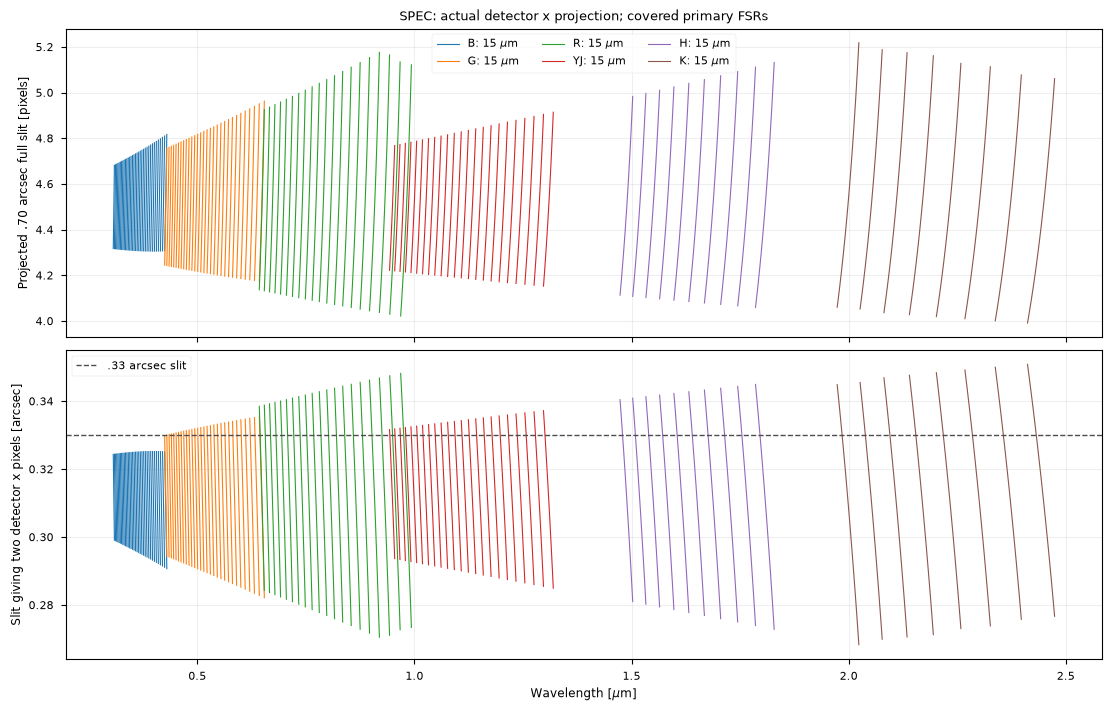

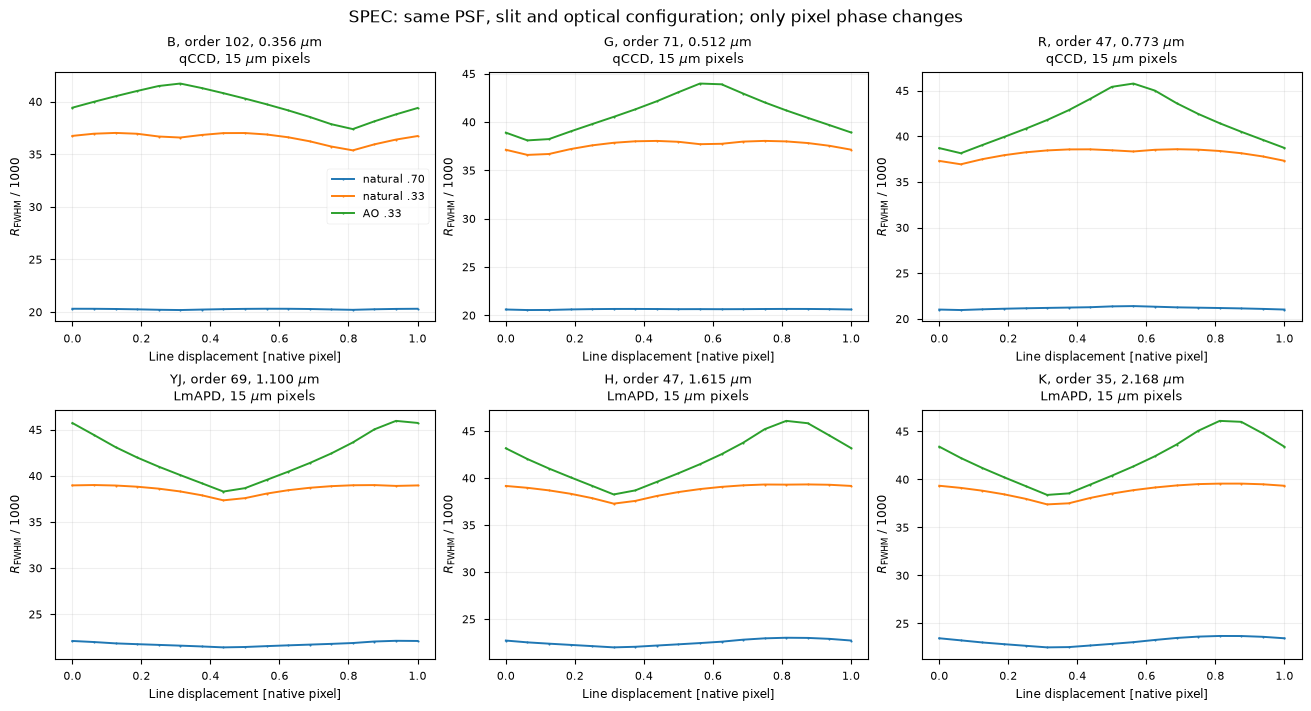

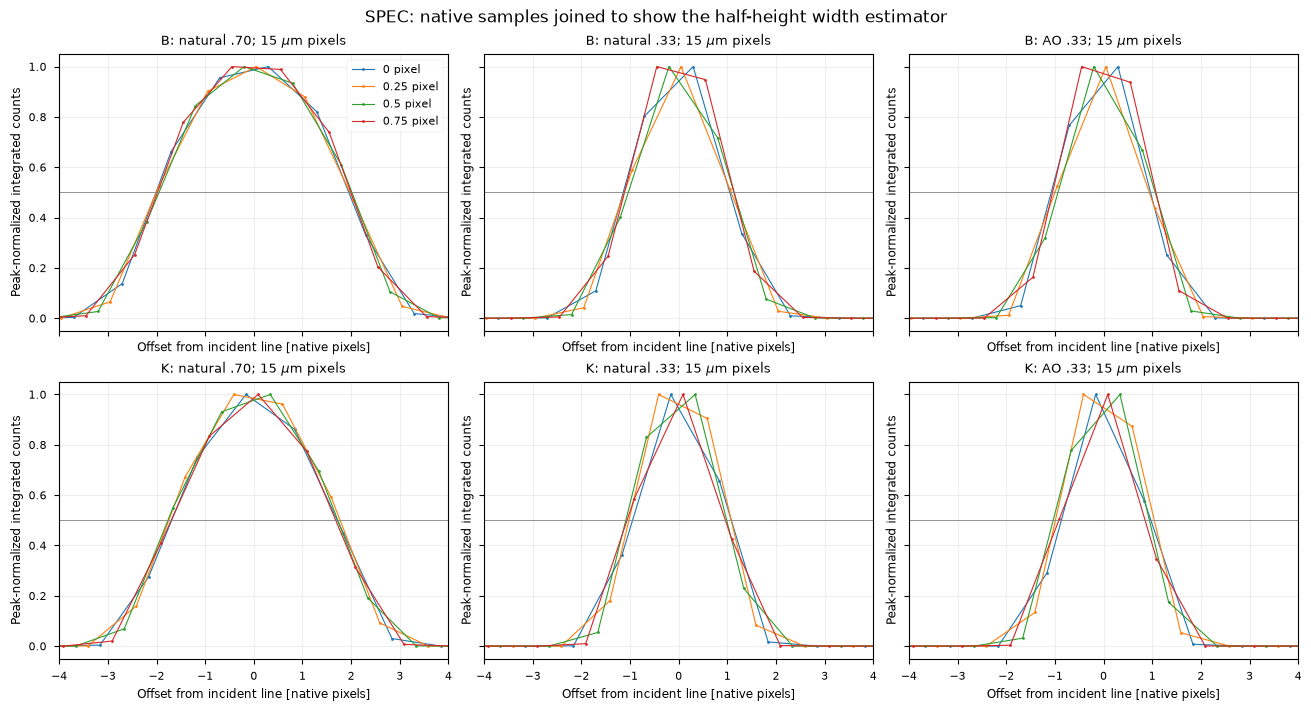

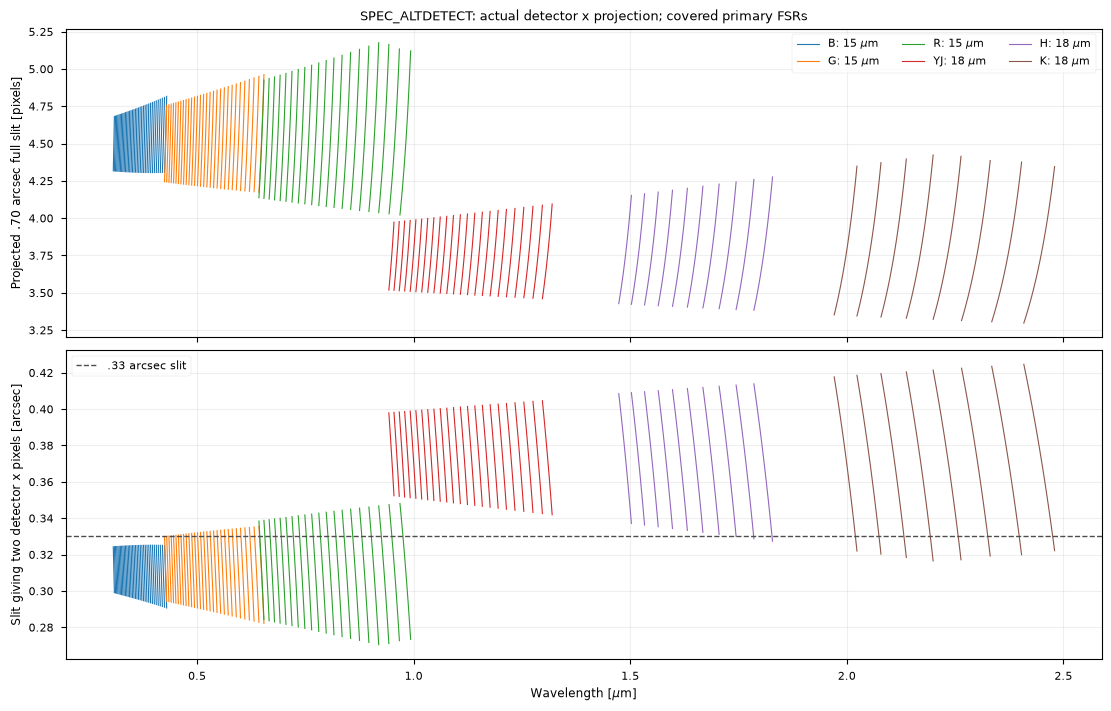

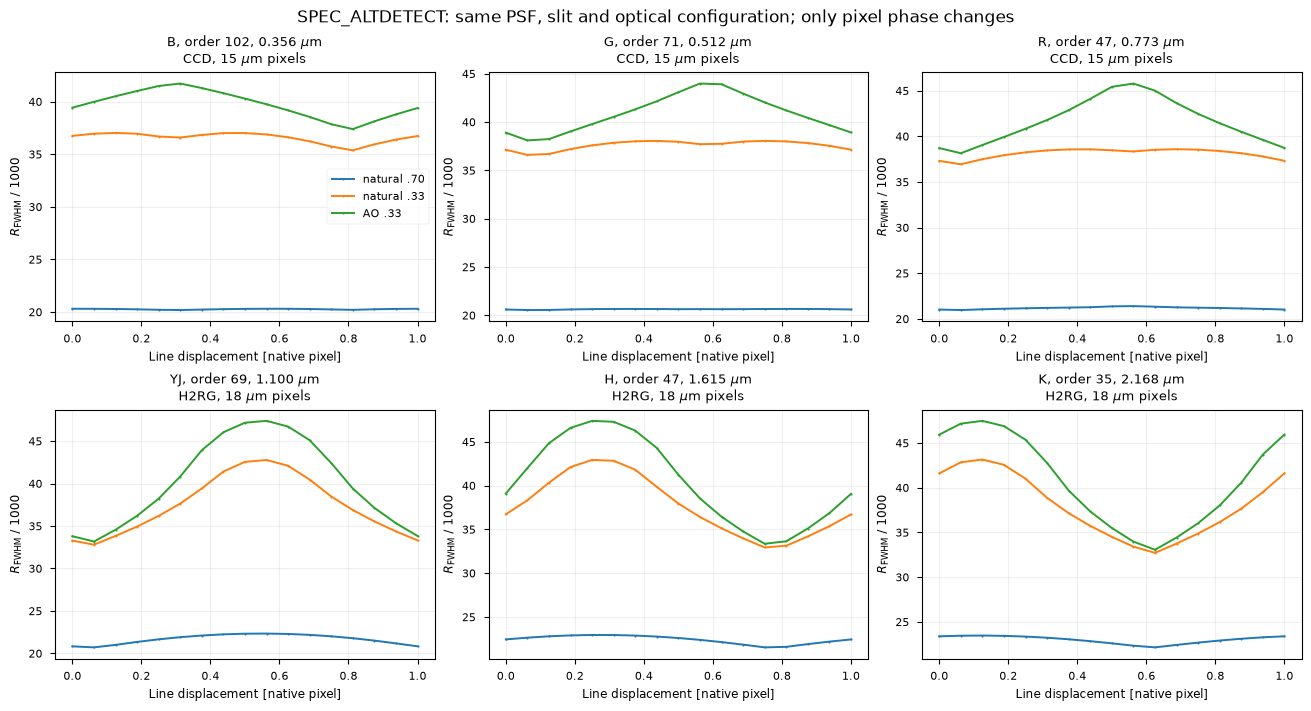

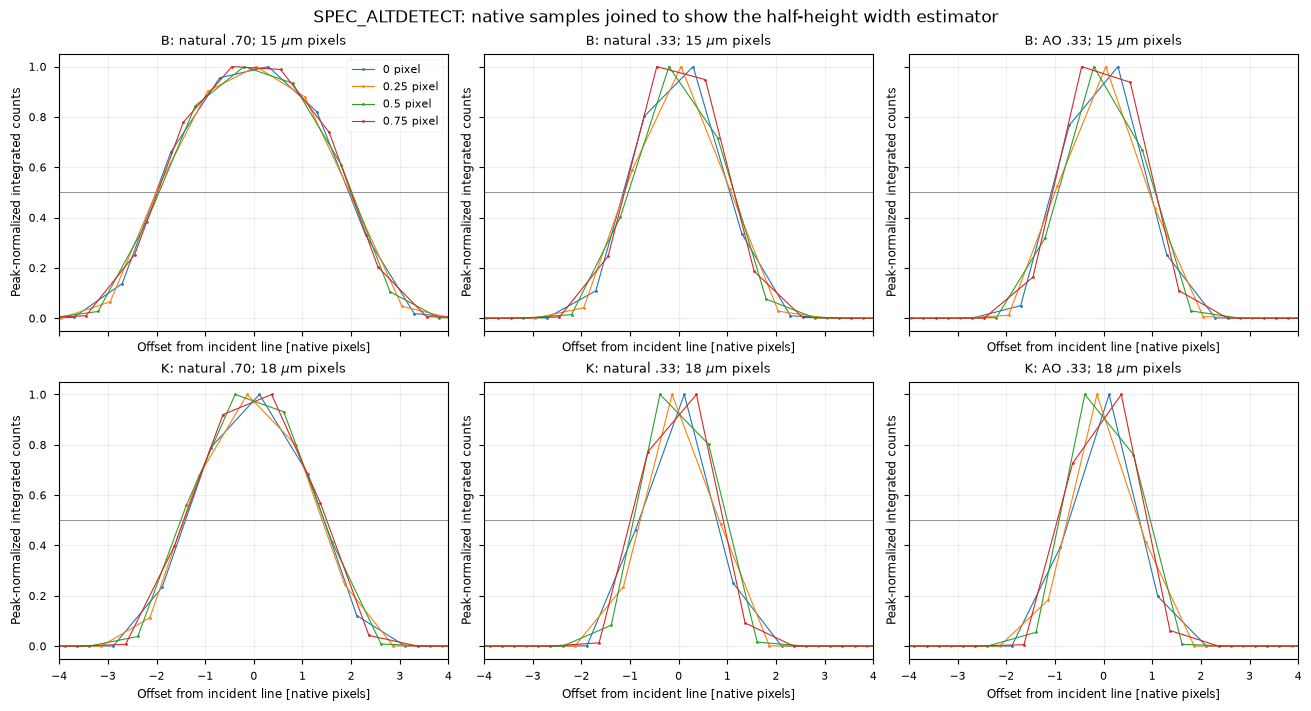

In [4]:
micron = r'$\mu$m'
for mode in DETECTOR_MODES:
    suffix = '' if mode == 'SPEC' else f'_{mode}'
    mode_detectors = detectors[detectors['mode'] == mode].set_index('channel')
    mode_geometry = geometry[(geometry['mode'] == mode) & geometry.on_detector]
    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout='constrained')
    for index, (channel, group) in enumerate(mode_geometry.groupby('channel', sort=False)):
        for order_index, (_, order_data) in enumerate(group.groupby('order')):
            label = f'{channel.upper()}: {mode_detectors.loc[channel, "pitch_um"]:g} {micron}' if order_index == 0 else None
            axes[0].plot(order_data.wavelength_um, order_data.slit_070_width_pixel, color=f'C{index}', lw=.8, label=label)
            axes[1].plot(order_data.wavelength_um, order_data.two_pixel_slit_arcsec, color=f'C{index}', lw=.8)
    axes[0].set(ylabel='Projected .70 arcsec full slit [pixels]', title=f'{mode}: actual detector x projection; covered primary FSRs')
    axes[0].legend(ncol=3)
    axes[1].axhline(.33, color='.3', ls='--', lw=1, label='.33 arcsec slit')
    axes[1].set(ylabel='Slit giving two detector x pixels [arcsec]', xlabel=r'Wavelength [$\mu$m]')
    axes[1].legend()
    for ax in axes:
        ax.grid(alpha=.2)
    assert len(axes[0].lines) == mode_geometry.groupby(['channel', 'order']).ngroups
    fig.savefig(output/f'slit_sampling{suffix}.png', dpi=170)
    plt.show()
    plt.close(fig)

    mode_phases = phases[phases['mode'] == mode]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout='constrained')
    for ax, (channel, group) in zip(axes.flat, mode_phases.groupby('channel', sort=False), strict=True):
        for name, selected in group.groupby('configuration', sort=False):
            ax.plot(selected.displacement_pixel, selected.R_fwhm/1000, '.-', ms=3, label=name)
        detector = mode_detectors.loc[channel]
        title = f'{channel.upper()}, order {group.order.iloc[0]}, {group.wavelength_um.iloc[0]:.3f} {micron}\n{detector.detector_type}, {detector.pitch_um:g} {micron} pixels'
        ax.set(title=title, xlabel='Line displacement [native pixel]', ylabel=r'$R_{\mathrm{FWHM}}$ / 1000')
        ax.grid(alpha=.2)
        assert len(ax.lines) == len(cases)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f'{mode}: same PSF, slit and optical configuration; only pixel phase changes')
    fig.savefig(output/f'pixel_phase{suffix}.png', dpi=170)
    plt.show()
    plt.close(fig)

    mode_profiles = profiles[profiles['mode'] == mode]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True, layout='constrained')
    for row, channel in enumerate(('b', 'k')):
        for column, (name, _, _) in enumerate(cases):
            ax = axes[row, column]
            selected = mode_profiles[(mode_profiles.channel == channel) & (mode_profiles.configuration == name)]
            for displacement, group in selected.groupby('displacement_pixel'):
                ax.plot(group.offset_pixel, group.normalized_counts, '.-', ms=4, lw=.8, label=f'{displacement:g} pixel')
            ax.axhline(.5, color='.5', lw=.6)
            title = f'{channel.upper()}: {name}; {mode_detectors.loc[channel, "pitch_um"]:g} {micron} pixels'
            ax.set(title=title, xlim=(-4, 4), xlabel='Offset from incident line [native pixels]', ylabel='Peak-normalized integrated counts')
            ax.grid(alpha=.2)
            assert len(ax.lines) == 5
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{mode}: native samples joined to show the half-height width estimator')
    fig.savefig(output/f'profiles{suffix}.png', dpi=170)
    plt.show()
    plt.close(fig)

## Interpretation of the executed run

The 2026-10-21 run used 15 micrometre pixels throughout `SPEC` and 18 micrometre H2RG pixels in the alternate YJ/H/K arms. Geometric slit resolving power is unchanged. At the representative NIR order centers, the alternate .33 arcsec AO profile spans approximately 1.4--2.0 pixels FWHM and its half-height estimate ranges from roughly 33,000 to 47,500 as pixel phase changes. This is greater sampling sensitivity, not extra optical resolving power. B/G/R match between modes in this noiseless experiment.

The clean-kernel run of 612 projections plus 36 quadrature checks took 57 seconds including fresh train setup. Refinement stayed within 0.24% in flux, 0.101% in FWHM and 0.00024 native pixel in centroid. The [report](../docs/resolution-and-sampling.md) gives the geometric and physical interpretation, both detector-mode tables, and the distinction between two-pixel sampling and a Nyquist criterion. The plots here are native sampled profiles; a pixel-integrated LSF fit is still a separate measurement improvement.